# Example: A Synthetic Market of Many Stocks
In this example, we extend the jump hidden Markov model from one asset to a universe of stocks. Each synthetic stock is built from a market draw and a sector draw that it shares with other stocks, plus a draw of its own. We check that the synthetic stocks move together the way the real ones do, and save the generator so we can use its synthetic markets later.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Separate market, sector, and own moves:__ Fit the single index model to each stock, and build each sector's factor from the residuals of the stocks in that sector.
> * __Build and simulate the sector factor model:__ Fit a jump hidden Markov model to the market, to each sector factor, and to each stock, and compose synthetic stocks from shared and own draws.
> * __Compare synthetic and real co-movement:__ Compare correlations within and across sectors, and each stock's volatility and market sensitivity, between a synthetic path and the real data, and let the market sensitivity drift over time.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We load the 2014 to 2024 daily price data with [the `MyTrainingMarketDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyTrainingMarketDataSet) and the GICS sector of each S&P 500 firm with [the `MySP500SectorDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MySP500SectorDataSet).

Our universe is `SPY` plus two stocks from each of the 11 GICS sectors. The sector factor model needs at least two stocks in every sector, and their single index residuals must move together, so we chose two closely related businesses in each sector whose residuals are positively correlated. Not every pair works: two stocks can sit in the same sector and still have residuals that move in opposite directions, and then the fit stops with an error that names the sector. We store the tickers in the `tickers::Array{String,1}` variable (`SPY` first), the closing prices in the `prices::Array{Float64,2}` variable (days × tickers), and the sector of each stock in the `sectors::Array{String,1}` variable:

In [2]:
tickers, prices, sectors = let

    # initialize: two stocks per sector, chosen so their single index residuals are positively correlated -
    universe = ["AAPL", "MSFT", "CMCSA", "VZ", "HD", "LOW", "PG", "KO", "XOM", "CVX", "JPM", "BAC",
        "JNJ", "MRK", "CAT", "DE", "SHW", "PPG", "PLD", "AMT", "NEE", "DUK"];
    dataset = MyTrainingMarketDataSet()["dataset"]; # 2014 to 2024, one DataFrame per ticker
    sector_table = MySP500SectorDataSet(); # GICS sector of each firm
    sector_of = Dict(String(r.Symbol) => String(r."GICS Sector") for r ∈ eachrow(sector_table));

    # the universe, its closing prices, and the sector of each stock -
    tickers = vcat("SPY", universe);
    prices = hcat([Float64.(dataset[t].close) for t ∈ tickers]...); # days × tickers (USD/share)
    sectors = [sector_of[t] for t ∈ universe]; # one label per stock, SPY excluded

    # checks: full history for every ticker, and two stocks in every sector -
    @assert all(nrow(dataset[t]) == nrow(dataset["SPY"]) for t ∈ tickers) "every ticker needs the full 2014-2024 history"
    @assert all(count(==(s), sectors) >= 2 for s ∈ unique(sectors)) "every sector needs at least two stocks"

    # return -
    (tickers, prices, sectors)
end;

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. As in the single-asset example, the growth rate is $g_{t} = \frac{1}{\Delta t}\ln\left(S_{t}/S_{t-1}\right)$ (units: 1/yr) with $\Delta t = 1/252$:

In [3]:
Δt = 1/252; # one trading day, expressed in years
number_of_states = 100; # number of hidden states in every jump hidden Markov model
ν = 5.0; # degrees of freedom of the Student-t distribution in each state
random_seed = 5660; # fix the random numbers, so every run gives the same paths
ϵ_range = range(1e-4, 5e-3, length = 6); # jump probabilities (per day) to search when tuning
λ_range = range(10.0, 160.0, length = 6); # mean episode lengths (days) to search when tuning
G = JumpHMM.excess_growth_rates(prices; rf = 0.0, dt = Δt); # daily growth rates, days × tickers (1/yr)
number_of_days = size(G, 1); # number of growth rates (trading days)
number_of_stocks = length(tickers) - 1; # stocks in the universe, SPY excluded

___

## Task 1: Separate Market, Sector, and Own Moves
In this task, we fit the sector factor model. The daily growth rate of stock $i$ in sector $s$ is built from three draws:
$$
g_{i}(t) = \alpha_{i} + \beta_{i}\,g_{m}(t) + \delta_{i}\,f_{s}(t) + \psi_{i}\,\tilde{\varepsilon}_{i}(t)
$$
where $g_{m}(t)$ is a draw of the market model, $f_{s}(t)$ a draw of the model of the stock's sector, and $\tilde{\varepsilon}_{i}(t)$ a draw of the stock's own model, centered on that model's long-run mean. The [`JumpHMM.fit(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/sector_factor/) fits the pieces:
* __Market:__ $\alpha_{i}$ and $\beta_{i}$ from the single index model of each stock on `SPY`, held fixed, and a jump hidden Markov model of `SPY`.
* __Sector:__ the sector factor $f_{s}$ is the average single index residual of the stocks in sector $s$, with its own jump hidden Markov model. The loading $\delta_{i}$ is the slope of the stock's residual on the other residuals in its sector, scaled so the sector's co-movement matches the data.
* __Own:__ a jump hidden Markov model of each stock, scaled by $\psi_{i}$ so each synthetic stock keeps its real variance.

We save the fitted model in the `portfolio::JumpHMM.PortfolioModel` variable. Each stock's long-run mean comes from one long draw of its model, of `center_steps` days:

In [4]:
portfolio = let

    # fit: market, sector, and own jump hidden Markov models, and the single index fits -
    time_to_fit = @elapsed portfolio = JumpHMM.fit(JumpHMM.PortfolioModel, tickers, prices;
        dependence = JumpHMM.SectorFactorModel, market = "SPY", sectors = sectors, N = number_of_states, ν = ν,
        rf = 0.0, dt = Δt, sector_options = (center_steps = 200_000,));
    println("fit in $(round(time_to_fit, digits = 1)) s");

    # checks: one model per stock and per sector -
    @assert length(portfolio.dependence.name_models) == number_of_stocks "one model per stock"
    @assert length(portfolio.dependence.sector_models) == length(unique(sectors)) "one model per sector"

    # return -
    portfolio
end;

fit in 2.4 s


Let's look at what the fit found for each stock: its sector, the single index $\hat{\alpha}_{i}$ (units: 1/yr), $\hat{\beta}_{i}$, and $R^{2}$, and its sector loading $\delta_{i}$:

In [5]:
let

    # initialize: the fitted sector factor model -
    dep = portfolio.dependence;

    # one row per stock -
    df = DataFrame(ticker = dep.tickers, sector = dep.sector, α = dep.α, β = dep.β, R² = dep.r², δ = dep.δ);
    pretty_table(df; column_labels = ["ticker", "sector", "α̂ (1/yr)", "β̂", "R²", "δ"],
        alignment = [:l, :l, :r, :r, :r, :r], formatters = [fmt__printf("%.3f", [3, 4, 5, 6])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 -------- ------------------------ ---------- ------- ------- -------
  ticker   sector                   α̂ (1/yr)       β̂      R²       δ 
 -------- ------------------------ ---------- ------- ------- -------
  AAPL     Information Technology      0.108   1.186   0.538   0.666
  MSFT     Information Technology      0.094   1.206   0.617   0.498
  CMCSA    Communication Services     -0.057   0.867   0.367   0.637
  VZ       Communication Services     -0.066   0.457   0.168   0.507
  HD       Consumer Discretionary      0.037   0.989   0.506   0.695
  LOW      Consumer Discretionary      0.034   1.065   0.424   1.119
  PG       Consumer Staples            0.009   0.547   0.274   0.829
  KO       Consumer Staples           -0.023   0.586   0.328   0.736
  XOM      Energy                     -0.085   0.872   0.309   0.890
  CVX      Energy                     -0.092   0.996   0.353   0.952
  JPM      Financials                  0.010   1.112   0.520   0.796
  BAC      Financials        

> __What do we see?__ The market explains only part of each stock's daily moves: the $R^{2}$ values are well below one. Every sector loading is positive, so the residuals of the two stocks in each sector move together, and the sector factor carries part of what the market leaves unexplained.
___

## Task 2: Simulate the Synthetic Universe
In this task, we tune the jump episodes of every model and simulate one synthetic path of the whole universe, as long as the data. [The `JumpHMM.tune(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/tuning/) tunes the market model, each sector model, and each stock's model on the same grid as the single-asset example. [The `JumpHMM.sample_dependence(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/sector_factor/) draws one path: on each day, every stock in a sector shares the same market draw and the same sector draw.

We save the tuned model in the `tuned::JumpHMM.PortfolioModel` variable and the synthetic growth rates of the stocks in the `G_syn::Array{Float64,2}` variable (days × stocks):

In [6]:
tuned, G_syn, g_m_syn = let

    # tune: every model in the universe, on the classroom grid -
    time_to_tune = @elapsed tuned = JumpHMM.tune(portfolio, prices; ϵ_range = ϵ_range, λ_range = λ_range,
        n_paths = 50, seed = random_seed);
    println("tuned in $(round(time_to_tune, digits = 1)) s");

    # simulate one path of the whole universe -
    d = JumpHMM.sample_dependence(tuned.dependence, number_of_days; seed = random_seed);
    println("stocks whose loadings were shrunk to keep their variance: $(count(d.n_clipped .> 0)) of $(number_of_stocks)");

    # checks: one column per stock, finite growth rates -
    @assert size(d.G) == (number_of_days, number_of_stocks) "unexpected size of the synthetic path"
    @assert all(isfinite, d.G) "synthetic growth rates must be finite"

    # return -
    (tuned, d.G, d.g_m)
end;

tuned in 16.8 s
stocks whose loadings were shrunk to keep their variance: 2 of 22


Let's compare how the stocks move together. The table shows the average correlation of daily growth rates between pairs of stocks in the same sector and in different sectors, for the real data and the synthetic path:

In [7]:
let

    # initialize: correlation matrices of the real and synthetic growth rates of the stocks -
    G_real = G[:, 2:end]; # drop SPY
    sector_index = tuned.dependence.sector_index;
    pairs_within = [(i, j) for i ∈ 1:number_of_stocks for j ∈ (i+1):number_of_stocks if sector_index[i] == sector_index[j]];
    pairs_across = [(i, j) for i ∈ 1:number_of_stocks for j ∈ (i+1):number_of_stocks if sector_index[i] != sector_index[j]];
    average(C, pairs) = mean(C[i, j] for (i, j) ∈ pairs); # average correlation over a set of pairs

    # one row per kind of pair -
    C_real = cor(G_real); # real correlation matrix
    C_syn = cor(G_syn); # synthetic correlation matrix
    df = DataFrame(pairs = ["same sector", "different sectors"],
        real = [average(C_real, pairs_within), average(C_real, pairs_across)],
        synthetic = [average(C_syn, pairs_within), average(C_syn, pairs_across)]);
    pretty_table(df; column_labels = ["pairs of stocks", "real", "synthetic"], alignment = [:l, :r, :r],
        formatters = [fmt__printf("%.3f", [2, 3])], table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);
end

 ------------------- ------- -----------
  pairs of stocks      real   synthetic 
 ------------------- ------- -----------
  same sector         0.670       0.687
  different sectors   0.391       0.380
 ------------------- ------- -----------


`Unhide` the code block below to see how we plotted the two correlation matrices, with the stocks in sector order, so each sector is a 2 × 2 block on the diagonal.

> __What do we see?__ Both matrices show the sector blocks on the diagonal, and the average correlation within a sector is close to the real one. Across sectors, the synthetic correlation is also close to the real one on this path. The sector models are drawn independently, so the shared market draw is the only link between two sectors.

Do the synthetic stocks move together like the real ones?

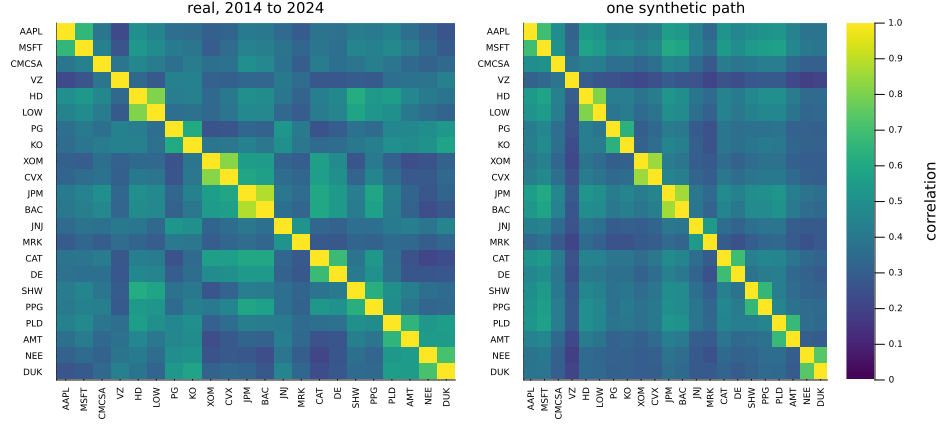

In [8]:
let

    # initialize: correlation matrices, stocks in sector order -
    labels = tuned.dependence.tickers;
    C_real = cor(G[:, 2:end]); # real correlation matrix
    C_syn = cor(G_syn); # synthetic correlation matrix

    # plot: real and synthetic, on one color scale -
    ticks = (1:length(labels), labels); # label every stock
    p1 = heatmap(C_real, clims = (0, 1), c = :viridis, yflip = true, title = "real, 2014 to 2024", xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar = false)
    p2 = heatmap(C_syn, clims = (0, 1), c = :viridis, yflip = true, title = "one synthetic path", xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar_title = "correlation")
    plot(p1, p2, layout = (1, 2), size = (950, 430), bottom_margin = 5Plots.mm)
end

Finally, let's compare each stock's volatility and β. For the synthetic path, we fit the single index model to the synthetic stock and the synthetic market draw:

In [9]:
let

    # initialize: the real and synthetic market growth rates -
    g_m_real = G[:, 1]; # real market growth rates (1/yr)
    X_real = hcat(ones(number_of_days), g_m_real); # regressors for the real single index fit
    X_syn = hcat(ones(number_of_days), g_m_syn); # regressors for the synthetic single index fit

    # one row per stock: annualized volatility and single index β, real and synthetic -
    vol(x) = std(x) * sqrt(Δt); # annualized volatility of daily growth rates (1/sqrt(yr))
    df = DataFrame(ticker = tuned.dependence.tickers,
        vol_real = [vol(G[:, i + 1]) for i ∈ 1:number_of_stocks], vol_syn = [vol(G_syn[:, i]) for i ∈ 1:number_of_stocks],
        β_real = [(X_real \ G[:, i + 1])[2] for i ∈ 1:number_of_stocks], β_syn = [(X_syn \ G_syn[:, i])[2] for i ∈ 1:number_of_stocks]);
    pretty_table(df; column_labels = ["ticker", "volatility, real", "volatility, synthetic", "β, real", "β, synthetic"],
        alignment = [:l, :r, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4, 5])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
    println("median ratio of synthetic to real volatility: $(round(median(df.vol_syn ./ df.vol_real), digits = 3))");
end

 -------- ------------------ ----------------------- --------- --------------
  ticker   volatility, real   volatility, synthetic   β, real   β, synthetic 
 -------- ------------------ ----------------------- --------- --------------
  AAPL                0.279                   0.296     1.186          1.199
  MSFT                0.265                   0.273     1.206          1.180
  CMCSA               0.247                   0.260     0.867          0.864
  VZ                  0.192                   0.210     0.457          0.460
  HD                  0.240                   0.256     0.989          0.966
  LOW                 0.282                   0.300     1.065          1.068
  PG                  0.181                   0.190     0.547          0.561
  KO                  0.177                   0.189     0.586          0.588
  XOM                 0.271                   0.309     0.872          0.875
  CVX                 0.290                   0.325     0.996          1.

> __What do we see?__ Each synthetic stock's β is close to its real value, because the model holds β at the single index fit. Each synthetic volatility is a little above the real one, by about the median ratio printed below the table: the model scales each stock's own draw to the real variance, and the jump episodes then add some large moves.
___

## Task 3: An Option: a Drifting β
In this task, we relax one simplification. So far, each stock's β is fixed at its single index fit. Real β wanders over time, and a trading method that re-estimates β as it trades faces that wander. The sector factor model can let β drift around $\hat{\beta}_{i}$ as a slow exponential moving average of random shocks, with half-life $h$ (trading days) and scale $k_{i}$:
$$
x_{i}(t) = (1-a)\,x_{i}(t-1) + a\,k_{i}\,z_{i}(t), \qquad \beta_{i}(t) = \hat{\beta}_{i} + x_{i}(t), \qquad a = 1 - 2^{-1/h}
$$
where $z_{i}(t)$ is a standard normal shock. The drift has standard deviation $k_{i}\sqrt{a/(2-a)}$.

To size $k_{i}$, we measure how much each stock's β wanders in the real data. An __online__ estimate of β refits the single index model each day by exponentially weighted least squares, which weights recent days more: a day $h$ trading days old counts half as much as today. [The `ewls_path(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/adaptive/#VLQuantitativeFinancePackage.ewls_path) returns the online $\alpha$, β, and residual standard deviation after each day. We set $k_{i}$ so the drift's standard deviation equals the standard deviation of the online β after its first year, once the estimate has settled. The online β also moves because of estimation noise, so this sizes the drift on the generous side.

We refit and retune the model with the drift on, and save it in the `drifting::JumpHMM.PortfolioModel` variable:

In [10]:
drifting = let

    # initialize: the half-life of the drift and of the online β estimate (trading days) -
    h = 126.0;
    a = 1 - 2^(-1 / h); # weight of the exponential moving average

    # the standard deviation of each stock's online β in the real data -
    sd_online = zeros(number_of_stocks);
    for i ∈ 1:number_of_stocks
        estimates = ewls_path(G[:, 1], G[:, i + 1]; half_life = h); # rows: (α, β, σ_ε) after each day
        β_online = estimates[253:end, 2]; # drop the first year, while the online estimate settles
        sd_online[i] = std(β_online);
    end
    β_scale = sd_online ./ sqrt(a / (2 - a)); # k_i, so the drift's standard deviation equals sd_online

    # refit and retune with the drift on -
    drifting = JumpHMM.fit(JumpHMM.PortfolioModel, tickers, prices; dependence = JumpHMM.SectorFactorModel,
        market = "SPY", sectors = sectors, N = number_of_states, ν = ν, rf = 0.0, dt = Δt,
        sector_options = (center_steps = 200_000, β_scale = β_scale, β_halflife = h));
    drifting = JumpHMM.tune(drifting, prices; ϵ_range = ϵ_range, λ_range = λ_range, n_paths = 50, seed = random_seed);
    println("standard deviation of the online β, median over the stocks: $(round(median(sd_online), digits = 3))");

    # checks: the drift is on, and its standard deviation matches the online β -
    @assert all(drifting.dependence.β_scale .> 0) "every stock should have a drifting β"
    @assert all(isapprox.(drifting.dependence.β_scale .* sqrt(a / (2 - a)), sd_online; rtol = 1e-10)) "drift SD should equal the online β SD"

    # return -
    drifting
end;

standard deviation of the online β, median over the stocks: 0.168


`Unhide` the code block below to see how we plotted the β of the first stock on one synthetic path with the drift on, next to its fixed β and its online β in the real data.

> __What do we see?__ The synthetic β wanders slowly around the single index fit, over months rather than days, as the online β does in the real data. With a fixed β, the synthetic stock would stay at the dashed line.

How does a drifting β move?

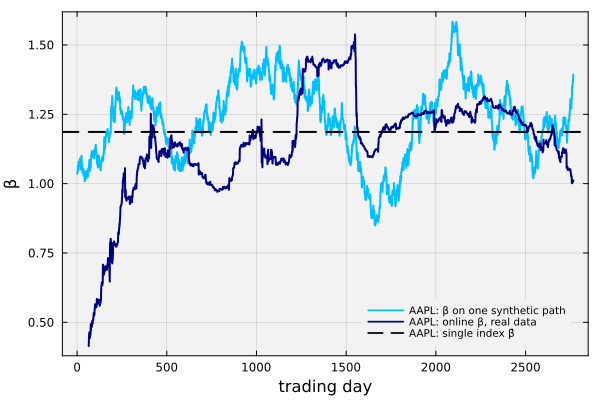

In [11]:
let

    # initialize: one synthetic path with the drift on, and the first stock's real online β -
    d = JumpHMM.sample_dependence(drifting.dependence, number_of_days; seed = random_seed);
    estimates = ewls_path(G[:, 1], G[:, 2]; half_life = 126.0);
    label = drifting.dependence.tickers[1];

    # plot: synthetic β path, real online β, and the fixed β -
    plot(1:number_of_days, d.β_eff[:, 1], lw = 2, c = :deepskyblue1, label = "$(label): β on one synthetic path",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    plot!(1:number_of_days, estimates[:, 2], lw = 2, c = :navy, label = "$(label): online β, real data")
    hline!([drifting.dependence.β[1]], lw = 2, c = :black, ls = :dash, label = "$(label): single index β̂")
    xlabel!("trading day"); ylabel!("β")
end

Finally, let's save the generator with the drift on, so the synthetic markets can be drawn again without refitting. We write it to `data/JumpHMM-SectorFactor-Universe-2014-2024.jld2`, with the tickers, the sectors, and the first day's closing prices, which turn synthetic growth rates back into prices:

In [12]:
let

    # save the generator and what it needs to rebuild prices -
    path = joinpath(_PATH_TO_DATA, "JumpHMM-SectorFactor-Universe-2014-2024.jld2");
    save(path, Dict("portfolio" => drifting, "tickers" => tickers, "sectors" => sectors, "first_close" => prices[1, :],
        "N" => number_of_states, "ν" => ν, "Δt" => Δt));

    # checks: the file reloads, and the reloaded generator draws the same path -
    reloaded = load(path, "portfolio");
    @assert JumpHMM.sample_dependence(reloaded.dependence, 10; seed = 1).G ==
        JumpHMM.sample_dependence(drifting.dependence, 10; seed = 1).G "the saved generator should reproduce the same draws"
end

___

## Summary
In this example, we extended the jump hidden Markov model from one asset to a universe of stocks with the sector factor model, compared a synthetic path with the real data, and saved the generator.

> __Key Takeaways:__
>
> * __Each stock splits into market, sector, and own moves:__ We fit the single index model to each stock and built each sector's factor from the residuals of its stocks. The market explained only part of each stock's moves, and the stocks in each sector shared a positive sector loading.
> * __Shared draws make synthetic stocks move together:__ We fit a jump hidden Markov model to the market, to each sector factor, and to each stock, and composed synthetic stocks from draws they share on the same day. On our synthetic path, the correlations within and across sectors were close to the real ones, and only the market links stocks in different sectors.
> * __Market sensitivity can be held fixed or allowed to drift:__ We held each stock's market sensitivity at its single index fit, then let it drift slowly, sized by how much the online estimate wanders in the real data, and saved that generator.

Understanding how the synthetic universe is built tells us which features of real markets a stress test on it can and cannot reproduce.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___